# environment setup + data load

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [21]:
from sklearn.preprocessing import PowerTransformer
import warnings
warnings.filterwarnings('ignore')

In [27]:
from sklearn.ensemble import IsolationForest

In [30]:
from sklearn.preprocessing import StandardScaler, RobustScaler

In [32]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [35]:
from sklearn.decomposition import PCA

In [36]:
# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [11]:
# Load data
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [12]:
# First look
print("Shape:", train.shape)
print("\nDtypes:\n", train.dtypes)
print("\nFirst 5 rows:")
train.head()

Shape: (103904, 25)

Dtypes:
 Unnamed: 0                             int64
id                                     int64
Gender                                object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness              

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.000,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.000,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.000,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.000,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.000,satisfied


# Structural Audit Code

In [13]:
# Drop junk columns
train.drop(columns=['Unnamed: 0', 'id'], inplace=True)
test.drop(columns=['Unnamed: 0', 'id'], inplace=True)

print("=== BASIC STRUCTURE ===")
print(f"Rows: {train.shape[0]:,} | Columns: {train.shape[1]}")

=== BASIC STRUCTURE ===
Rows: 103,904 | Columns: 23


In [14]:
print("\n=== MISSING VALUES ===")
missing = train.isnull().sum()
missing_pct = (missing / len(train)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
}).query('`Missing Count` > 0')
print(missing_df)

print("\n=== DUPLICATE ROWS ===")
print(f"Duplicates: {train.duplicated().sum()}")

print("\n=== TARGET DISTRIBUTION ===")
print(train['satisfaction'].value_counts())
print(train['satisfaction'].value_counts(normalize=True).mul(100).round(2))

print("\n=== ORDINAL FEATURE RANGES ===")
ordinal_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Inflight service', 'Cleanliness'
]
print(train[ordinal_cols].agg(['min', 'max', 'nunique']))


=== MISSING VALUES ===
                          Missing Count  Missing %
Arrival Delay in Minutes            310      0.298

=== DUPLICATE ROWS ===
Duplicates: 0

=== TARGET DISTRIBUTION ===
satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64
satisfaction
neutral or dissatisfied   56.670
satisfied                 43.330
Name: proportion, dtype: float64

=== ORDINAL FEATURE RANGES ===
         Inflight wifi service  Departure/Arrival time convenient  \
min                          0                                  0   
max                          5                                  5   
nunique                      6                                  6   

         Ease of Online booking  Gate location  Food and drink  \
min                           0              0               0   
max                           5              5               5   
nunique                       6              6               6   

         Online 

In [15]:
# Create a binary flag: 1 = arrival delay was missing
train['arrival_delay_missing'] = train['Arrival Delay in Minutes'].isnull().astype(int)

print("=== IS MISSINGNESS RELATED TO DEPARTURE DELAY? ===")
print(train.groupby('arrival_delay_missing')['Departure Delay in Minutes'].agg(['mean', 'median', 'count']))

print("\n=== IS MISSINGNESS RELATED TO TARGET? ===")
print(train.groupby('arrival_delay_missing')['satisfaction'].value_counts(normalize=True))

print("\n=== IS MISSINGNESS RELATED TO CLASS? ===")
print(train.groupby('arrival_delay_missing')['Class'].value_counts(normalize=True))

print("\n=== DEPARTURE DELAY WHEN ARRIVAL IS MISSING ===")
missing_mask = train['arrival_delay_missing'] == 1
print("Departure delay stats where arrival is missing:")
print(train.loc[missing_mask, 'Departure Delay in Minutes'].describe())
print("\nDeparture delay stats where arrival is present:")
print(train.loc[~missing_mask, 'Departure Delay in Minutes'].describe())

=== IS MISSINGNESS RELATED TO DEPARTURE DELAY? ===
                        mean  median   count
arrival_delay_missing                       
0                     14.748   0.000  103594
1                     37.432   8.000     310

=== IS MISSINGNESS RELATED TO TARGET? ===
arrival_delay_missing  satisfaction           
0                      neutral or dissatisfied   0.567
                       satisfied                 0.433
1                      neutral or dissatisfied   0.587
                       satisfied                 0.413
Name: proportion, dtype: float64

=== IS MISSINGNESS RELATED TO CLASS? ===
arrival_delay_missing  Class   
0                      Business   0.478
                       Eco        0.450
                       Eco Plus   0.072
1                      Eco        0.490
                       Business   0.426
                       Eco Plus   0.084
Name: proportion, dtype: float64

=== DEPARTURE DELAY WHEN ARRIVAL IS MISSING ===
Departure delay stats where ar

In [16]:
print("=== ZERO COUNTS IN ORDINAL FEATURES ===")
zero_counts = pd.DataFrame({
    'Zero Count': (train[ordinal_cols] == 0).sum(),
    'Zero %': ((train[ordinal_cols] == 0).sum() / len(train) * 100).round(3)
}).sort_values('Zero %', ascending=False)
print(zero_counts)

print("\n=== ARE ZEROS RELATED TO SATISFACTION? ===")
# For the column with most zeros, check if zero-raters have different satisfaction
top_zero_col = zero_counts.index[0]
train['is_zero_rater'] = (train[top_zero_col] == 0).astype(int)
print(f"Column: {top_zero_col}")
print(train.groupby('is_zero_rater')['satisfaction'].value_counts(normalize=True))

# Clean up temp column
train.drop(columns=['is_zero_rater'], inplace=True)

=== ZERO COUNTS IN ORDINAL FEATURES ===
                                   Zero Count  Zero %
Departure/Arrival time convenient        5300   5.101
Ease of Online booking                   4487   4.318
Inflight wifi service                    3103   2.986
Online boarding                          2428   2.337
Leg room service                          472   0.454
Food and drink                            107   0.103
Inflight entertainment                     14   0.013
Cleanliness                                12   0.012
Inflight service                            3   0.003
On-board service                            3   0.003
Gate location                               1   0.001
Seat comfort                                1   0.001
Checkin service                             1   0.001
Baggage handling                            0   0.000

=== ARE ZEROS RELATED TO SATISFACTION? ===
Column: Departure/Arrival time convenient
is_zero_rater  satisfaction           
0              neutral or

In [17]:
from sklearn.linear_model import LinearRegression

print("=== CORRELATION: DEPARTURE vs ARRIVAL DELAY ===")
corr = train[['Departure Delay in Minutes', 'Arrival Delay in Minutes']].corr()
print(corr)

# Separate rows where arrival delay is present vs missing
present_mask = train['Arrival Delay in Minutes'].notna()
missing_mask = ~present_mask

# Fit regression on rows where both are present
X_train_imp = train.loc[present_mask, ['Departure Delay in Minutes']]
y_train_imp = train.loc[present_mask, 'Arrival Delay in Minutes']

reg = LinearRegression()
reg.fit(X_train_imp, y_train_imp)

print(f"\nRegression: Arrival = {reg.coef_[0]:.4f} * Departure + {reg.intercept_:.4f}")
print(f"R² score: {reg.score(X_train_imp, y_train_imp):.4f}")

# Impute missing values
X_missing = train.loc[missing_mask, ['Departure Delay in Minutes']]
train.loc[missing_mask, 'Arrival Delay in Minutes'] = reg.predict(X_missing)

# Verify
print(f"\nMissing after imputation: {train['Arrival Delay in Minutes'].isnull().sum()}")

# Also drop the flag column we made earlier - it served its purpose
train.drop(columns=['arrival_delay_missing'], inplace=True)

=== CORRELATION: DEPARTURE vs ARRIVAL DELAY ===
                            Departure Delay in Minutes  \
Departure Delay in Minutes                       1.000   
Arrival Delay in Minutes                         0.965   

                            Arrival Delay in Minutes  
Departure Delay in Minutes                     0.965  
Arrival Delay in Minutes                       1.000  

Regression: Arrival = 0.9802 * Departure + 0.7224
R² score: 0.9322

Missing after imputation: 0


In [18]:
test_present = test['Arrival Delay in Minutes'].notna()
test_missing = ~test_present
if test_missing.sum() > 0:
    test.loc[test_missing, 'Arrival Delay in Minutes'] = reg.predict(
        test.loc[test_missing, ['Departure Delay in Minutes']]
    )

In [19]:
# Tier 1: High zero rate — create binary "did not use" flag + keep rating as-is
# These zeros carry signal about passenger engagement
tier1_cols = [
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Inflight wifi service',
    'Online boarding'
]

for col in tier1_cols:
    flag_name = col.replace(' ', '_').replace('/', '_') + '_not_used'
    train[flag_name] = (train[col] == 0).astype(int)
    test[flag_name] = (test[col] == 0).astype(int)

print("=== TIER 1 FLAGS CREATED ===")
new_flag_cols = [c for c in train.columns if c.endswith('_not_used')]
print(train[new_flag_cols].sum())

# Tier 2 + 3: Low zero rate — replace 0 with NaN, then impute with median
# These zeros are errors, not information
tier2_3_cols = [col for col in ordinal_cols if col not in tier1_cols]

for col in tier2_3_cols:
    zero_count = (train[col] == 0).sum()
    if zero_count > 0:
        train[col] = train[col].replace(0, np.nan)
        test[col] = test[col].replace(0, np.nan)
        median_val = train[col].median()
        train[col] = train[col].fillna(median_val)
        test[col] = test[col].fillna(median_val)
        print(f"Fixed {col}: {zero_count} zeros → median {median_val}")

print("\n=== REMAINING ZEROS IN TIER 1 COLS (expected - preserved) ===")
print((train[tier1_cols] == 0).sum())

=== TIER 1 FLAGS CREATED ===
Departure_Arrival_time_convenient_not_used    5300
Ease_of_Online_booking_not_used               4487
Inflight_wifi_service_not_used                3103
Online_boarding_not_used                      2428
dtype: int64
Fixed Gate location: 1 zeros → median 3.0
Fixed Food and drink: 107 zeros → median 3.0
Fixed Seat comfort: 1 zeros → median 4.0
Fixed Inflight entertainment: 14 zeros → median 4.0
Fixed On-board service: 3 zeros → median 4.0
Fixed Leg room service: 472 zeros → median 4.0
Fixed Checkin service: 1 zeros → median 3.0
Fixed Inflight service: 3 zeros → median 4.0
Fixed Cleanliness: 12 zeros → median 3.0

=== REMAINING ZEROS IN TIER 1 COLS (expected - preserved) ===
Departure/Arrival time convenient    5300
Ease of Online booking               4487
Inflight wifi service                3103
Online boarding                      2428
dtype: int64


# Exploratory Data Analysis

### Distributions

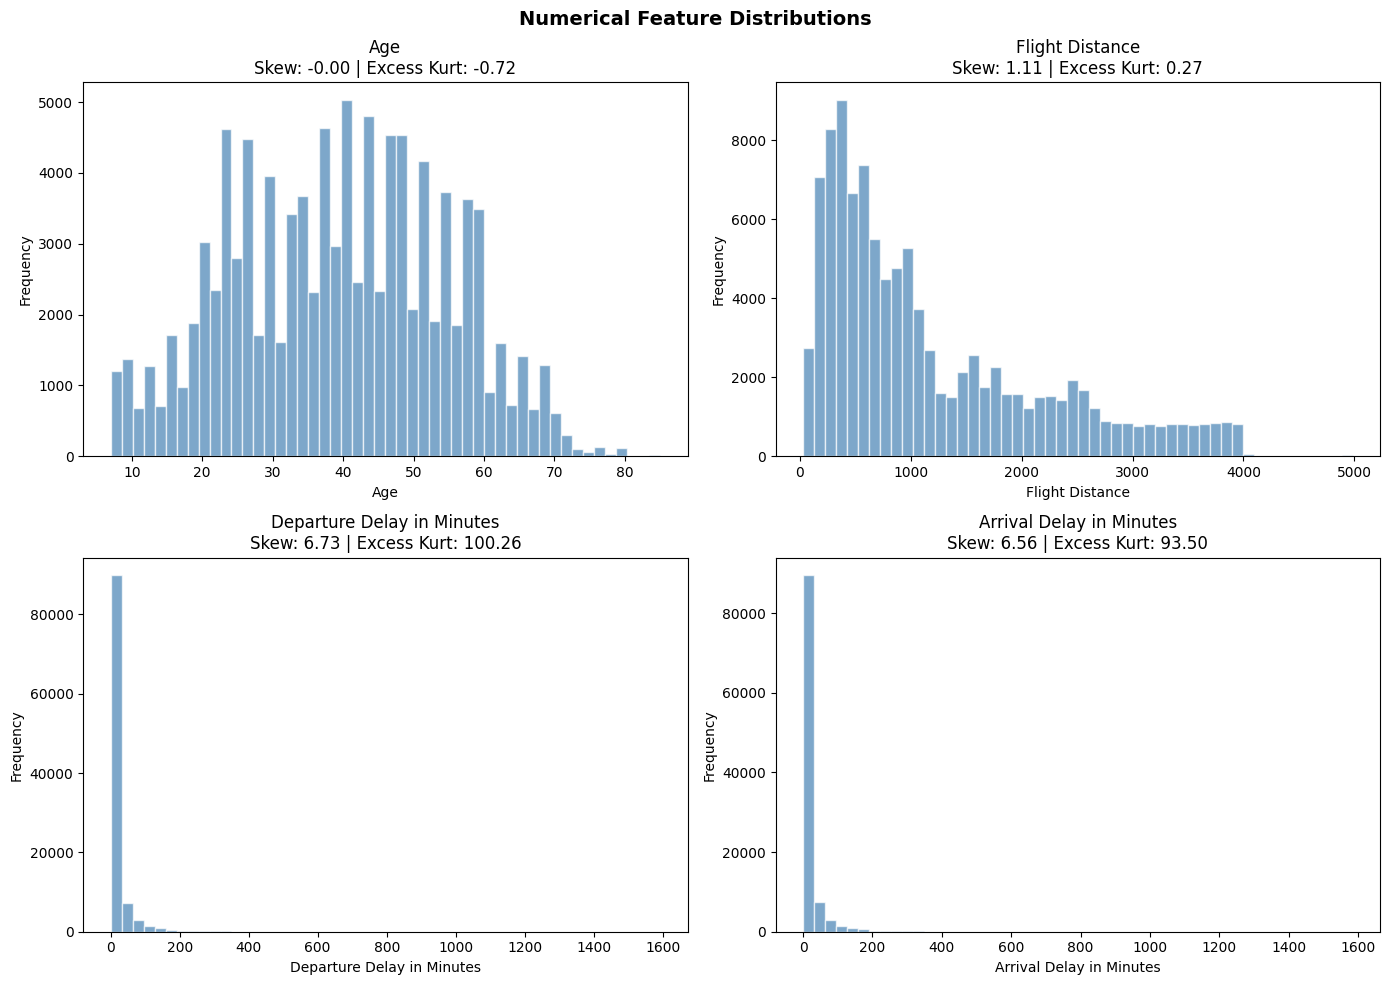

=== SKEWNESS & KURTOSIS ===

Age:
  Mean:     39.38
  Median:   40.00
  Skewness: -0.005
  Kurtosis: -0.720
  Min: 7 | Max: 85

Flight Distance:
  Mean:     1189.45
  Median:   843.00
  Skewness: 1.109
  Kurtosis: 0.268
  Min: 31 | Max: 4983

Departure Delay in Minutes:
  Mean:     14.82
  Median:   0.00
  Skewness: 6.734
  Kurtosis: 100.262
  Min: 0 | Max: 1592

Arrival Delay in Minutes:
  Mean:     15.25
  Median:   0.00
  Skewness: 6.565
  Kurtosis: 93.503
  Min: 0 | Max: 1584


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Numerical Feature Distributions', fontsize=14, fontweight='bold')

numerical_cols = ['Age', 'Flight Distance',
                  'Departure Delay in Minutes',
                  'Arrival Delay in Minutes']

for idx, col in enumerate(numerical_cols):
    ax = axes[idx // 2][idx % 2]

    data = train[col].dropna()
    skew = stats.skew(data)
    kurt = stats.kurtosis(data)  # excess kurtosis (normal = 0)

    ax.hist(data, bins=50, color='steelblue', alpha=0.7, edgecolor='white')
    ax.set_title(f'{col}\nSkew: {skew:.2f} | Excess Kurt: {kurt:.2f}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('distributions_numerical.png', dpi=150)
plt.show()

# Print exact values
print("=== SKEWNESS & KURTOSIS ===")
for col in numerical_cols:
    data = train[col].dropna()
    print(f"\n{col}:")
    print(f"  Mean:     {data.mean():.2f}")
    print(f"  Median:   {data.median():.2f}")
    print(f"  Skewness: {stats.skew(data):.3f}")
    print(f"  Kurtosis: {stats.kurtosis(data):.3f}")
    print(f"  Min: {data.min():.0f} | Max: {data.max():.0f}")

=== AFTER TRANSFORMATION ===

Flight Distance (transformed):
  Skewness: -0.027
  Kurtosis: -0.840
  Mean: -0.000 | Median: -0.013

Departure Delay (transformed):
  Skewness: 0.917
  Kurtosis: -0.557
  Mean: 1.236 | Median: 0.000

Arrival Delay (transformed):
  Skewness: 0.871
  Kurtosis: -0.641
  Mean: 1.268 | Median: 0.000

=== DELAY BINARY FLAGS ===
Departure delayed (>0 min): 0.435 of flights
Arrival delayed (>0 min): 0.44 of flights


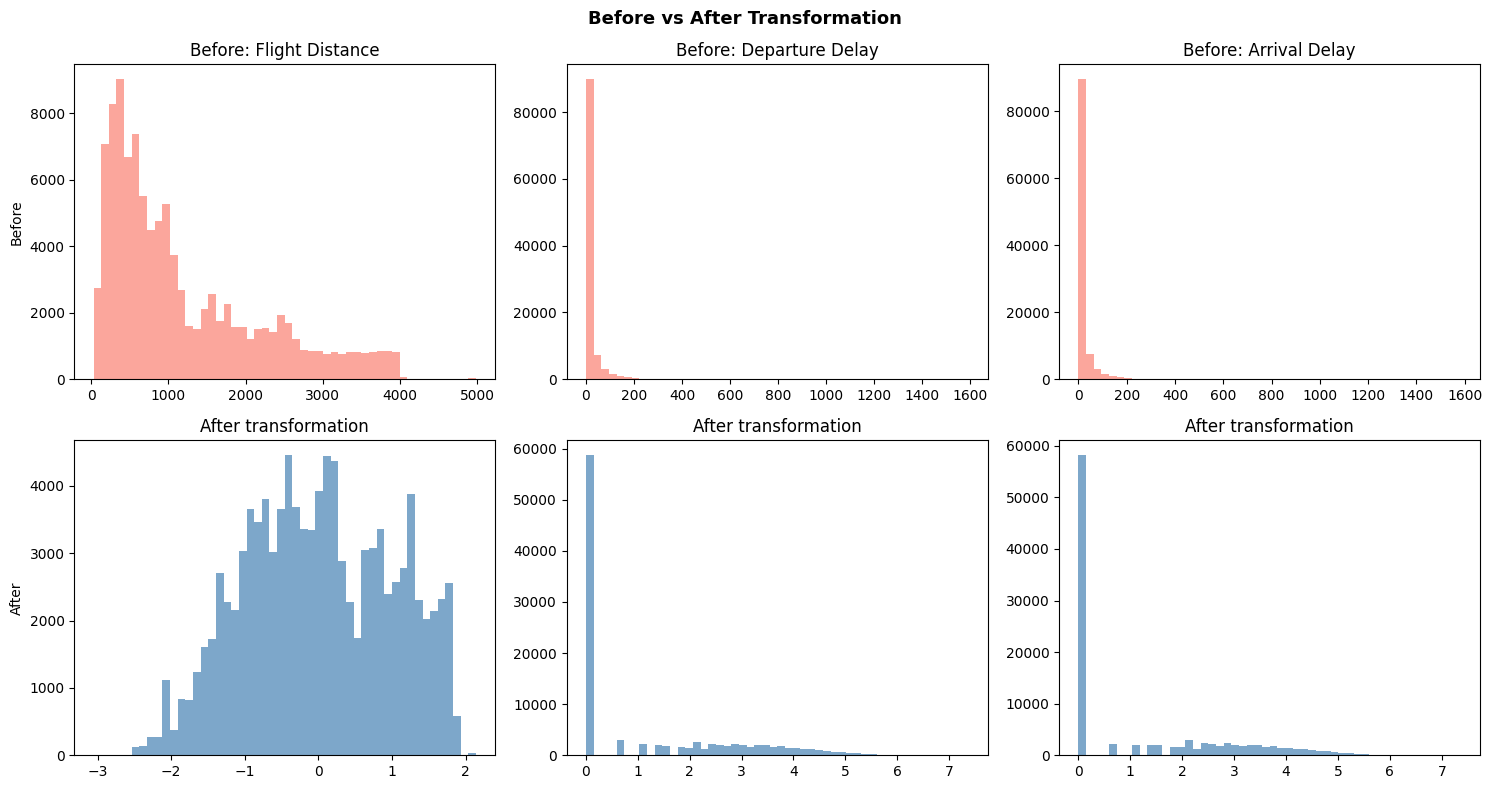

In [22]:
# --- Flight Distance: Yeo-Johnson ---
pt_distance = PowerTransformer(method='yeo-johnson')
train['Flight Distance Transformed'] = pt_distance.fit_transform(
    train[['Flight Distance']]
)
test['Flight Distance Transformed'] = pt_distance.transform(
    test[['Flight Distance']]
)

# --- Delay Columns: Zero-inflated treatment ---
for col in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
    flag_col = col.replace(' ', '_') + '_binary'
    transformed_col = col.replace(' ', '_') + '_transformed'

    # Step 1: Binary flag — was there any delay at all?
    train[flag_col] = (train[col] > 0).astype(int)
    test[flag_col] = (test[col] > 0).astype(int)

    # Step 2: Log1p transform on original
    # (log(0) = undefined, log(0+1) = 0, preserves zero mass)
    train[transformed_col] = np.log1p(train[col])
    test[transformed_col] = np.log1p(test[col])

# --- Verification ---
print("=== AFTER TRANSFORMATION ===")
check_cols = {
    'Flight Distance Transformed': 'Flight Distance',
    'Departure_Delay_in_Minutes_transformed': 'Departure Delay',
    'Arrival_Delay_in_Minutes_transformed': 'Arrival Delay'
}

for new_col, label in check_cols.items():
    data = train[new_col]
    print(f"\n{label} (transformed):")
    print(f"  Skewness: {stats.skew(data):.3f}")
    print(f"  Kurtosis: {stats.kurtosis(data):.3f}")
    print(f"  Mean: {data.mean():.3f} | Median: {data.median():.3f}")

print("\n=== DELAY BINARY FLAGS ===")
print("Departure delayed (>0 min):",
      train['Departure_Delay_in_Minutes_binary'].mean().round(3),
      "of flights")
print("Arrival delayed (>0 min):",
      train['Arrival_Delay_in_Minutes_binary'].mean().round(3),
      "of flights")

# Visual comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Before vs After Transformation', fontsize=13, fontweight='bold')

pairs = [
    ('Flight Distance', 'Flight Distance Transformed'),
    ('Departure Delay in Minutes', 'Departure_Delay_in_Minutes_transformed'),
    ('Arrival Delay in Minutes', 'Arrival_Delay_in_Minutes_transformed'),
]

for idx, (before, after) in enumerate(pairs):
    ax_before = axes[0][idx]
    ax_after = axes[1][idx]

    ax_before.hist(train[before], bins=50, color='salmon', alpha=0.7)
    ax_before.set_title(f'Before: {before.split(" ")[0]} {before.split(" ")[1] if len(before.split()) > 1 else ""}')

    ax_after.hist(train[after], bins=50, color='steelblue', alpha=0.7)
    ax_after.set_title(f'After transformation')

axes[0][0].set_ylabel('Before')
axes[1][0].set_ylabel('After')

plt.tight_layout()
plt.savefig('transformations.png', dpi=150)
plt.show()

### Categorical Feature Analysis

In [23]:
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

print("=== CATEGORICAL FEATURE ANALYSIS ===")
for col in categorical_cols:
    print(f"\n{'='*45}")
    print(f"Feature: {col}")
    print(f"Unique values: {train[col].nunique()}")
    print(f"Value counts:")
    vc = train[col].value_counts()
    pct = train[col].value_counts(normalize=True).mul(100).round(2)
    print(pd.concat([vc, pct], axis=1, keys=['Count', '%']))

print("\n\n=== SATISFACTION RATE BY CATEGORY ===")
for col in categorical_cols:
    print(f"\n{col}:")
    ct = pd.crosstab(
        train[col],
        train['satisfaction'],
        normalize='index'
    ).mul(100).round(2)
    print(ct)

=== CATEGORICAL FEATURE ANALYSIS ===

Feature: Gender
Unique values: 2
Value counts:
        Count      %
Gender              
Female  52727 50.750
Male    51177 49.250

Feature: Customer Type
Unique values: 2
Value counts:
                   Count      %
Customer Type                  
Loyal Customer     84923 81.730
disloyal Customer  18981 18.270

Feature: Type of Travel
Unique values: 2
Value counts:
                 Count      %
Type of Travel               
Business travel  71655 68.960
Personal Travel  32249 31.040

Feature: Class
Unique values: 3
Value counts:
          Count      %
Class                 
Business  49665 47.800
Eco       46745 44.990
Eco Plus   7494  7.210


=== SATISFACTION RATE BY CATEGORY ===

Gender:
satisfaction  neutral or dissatisfied  satisfied
Gender                                          
Female                         57.260     42.740
Male                           56.050     43.950

Customer Type:
satisfaction       neutral or dissatisfied  satis

In [24]:
print("=== TRAVEL TYPE × CLASS CROSSTAB ===")
ct = pd.crosstab(
    train['Type of Travel'],
    train['Class'],
    normalize='index'
).mul(100).round(2)
print(ct)

print("\n=== SATISFACTION RATE BY TRAVEL TYPE × CLASS ===")
interaction = train.groupby(['Type of Travel', 'Class'])['satisfaction'].apply(
    lambda x: (x == 'satisfied').mean() * 100
).round(2)
print(interaction)

print("\n=== CUSTOMER TYPE × TRAVEL TYPE ===")
ct2 = pd.crosstab(
    train['Customer Type'],
    train['Type of Travel'],
    normalize='index'
).mul(100).round(2)
print(ct2)

=== TRAVEL TYPE × CLASS CROSSTAB ===
Class            Business    Eco  Eco Plus
Type of Travel                            
Business travel    66.300 28.270     5.430
Personal Travel     6.690 82.140    11.180

=== SATISFACTION RATE BY TRAVEL TYPE × CLASS ===
Type of Travel   Class   
Business travel  Business   72.020
                 Eco        29.620
                 Eco Plus   39.330
Personal Travel  Business   12.240
                 Eco        10.200
                 Eco Plus    8.710
Name: satisfaction, dtype: float64

=== CUSTOMER TYPE × TRAVEL TYPE ===
Type of Travel     Business travel  Personal Travel
Customer Type                                      
Loyal Customer              62.220           37.780
disloyal Customer           99.140            0.860


### Encoding Categorical Features

In [25]:
# --- Binary encodings ---
train['is_loyal'] = (train['Customer Type'] == 'Loyal Customer').astype(int)
test['is_loyal'] = (test['Customer Type'] == 'Loyal Customer').astype(int)

train['is_business_travel'] = (train['Type of Travel'] == 'Business travel').astype(int)
test['is_business_travel'] = (test['Type of Travel'] == 'Business travel').astype(int)

train['is_male'] = (train['Gender'] == 'Male').astype(int)
test['is_male'] = (test['Gender'] == 'Male').astype(int)

# --- One-hot encode Class ---
train = pd.get_dummies(train, columns=['Class'], prefix='class', drop_first=False)
test = pd.get_dummies(test, columns=['Class'], prefix='class', drop_first=False)

# --- Interaction feature: Travel Type × Class ---
# Encodes the 6 combinations we analyzed above
# Business travel + Business class = the high-satisfaction anchor
train['business_travel_x_business_class'] = (
    (train['is_business_travel'] == 1) &
    (train['class_Business'] == 1)
).astype(int)

train['personal_travel_x_eco'] = (
    (train['is_business_travel'] == 0) &
    (train['class_Eco'] == 1)
).astype(int)

# The underperforming segment — Eco Plus personal travelers
train['ecoplus_personal'] = (
    (train['is_business_travel'] == 0) &
    (train['class_Eco Plus'] == 1)
).astype(int)

test['business_travel_x_business_class'] = (
    (test['is_business_travel'] == 1) &
    (test['class_Business'] == 1)
).astype(int)

test['personal_travel_x_eco'] = (
    (test['is_business_travel'] == 0) &
    (test['class_Eco'] == 1)
).astype(int)

test['ecoplus_personal'] = (
    (test['is_business_travel'] == 0) &
    (test['class_Eco Plus'] == 1)
).astype(int)

# --- Encode target ---
train['satisfaction_binary'] = (train['satisfaction'] == 'satisfied').astype(int)
test['satisfaction_binary'] = (test['satisfaction'] == 'satisfied').astype(int)

# --- Drop original categorical columns now that they're encoded ---
cols_to_drop = ['Gender', 'Customer Type', 'Type of Travel', 'satisfaction']
train.drop(columns=cols_to_drop, inplace=True)
test.drop(columns=cols_to_drop, inplace=True)

# --- Verify ---
print("=== ENCODING VERIFICATION ===")
print(f"Train shape: {train.shape}")
print(f"\nNew columns added:")
new_cols = ['is_loyal', 'is_business_travel', 'is_male',
            'class_Business', 'class_Eco', 'class_Eco Plus',
            'business_travel_x_business_class',
            'personal_travel_x_eco', 'ecoplus_personal',
            'satisfaction_binary']
print(train[new_cols].head(10))

print(f"\n=== INTERACTION FEATURE SATISFACTION RATES ===")
for col in ['business_travel_x_business_class',
            'personal_travel_x_eco', 'ecoplus_personal']:
    rate = train.groupby(col)['satisfaction_binary'].mean().mul(100).round(2)
    print(f"\n{col}:")
    print(rate)

=== ENCODING VERIFICATION ===
Train shape: (103904, 37)

New columns added:
   is_loyal  is_business_travel  is_male  class_Business  class_Eco  \
0         1                   0        1           False      False   
1         0                   1        1            True      False   
2         1                   1        0            True      False   
3         1                   1        0            True      False   
4         1                   1        1            True      False   
5         1                   0        0           False       True   
6         1                   0        1           False       True   
7         1                   1        0            True      False   
8         1                   1        0            True      False   
9         0                   1        1           False       True   

   class_Eco Plus  business_travel_x_business_class  personal_travel_x_eco  \
0            True                                 0             

In [26]:
bool_cols = train.select_dtypes(include='bool').columns.tolist()
print("Boolean columns found:", bool_cols)

train[bool_cols] = train[bool_cols].astype(int)
test[bool_cols] = test[bool_cols].astype(int)

print("Fixed. Dtypes now:")
print(train[bool_cols].dtypes)

Boolean columns found: ['class_Business', 'class_Eco', 'class_Eco Plus']
Fixed. Dtypes now:
class_Business    int64
class_Eco         int64
class_Eco Plus    int64
dtype: object


### Outlier Detection

In [28]:
numerical_cols = ['Age', 'Flight Distance',
                  'Departure Delay in Minutes',
                  'Arrival Delay in Minutes']

# --- Method 1: Z-score ---
print("=== Z-SCORE OUTLIERS (|z| > 3) ===")
z_outlier_counts = {}
for col in numerical_cols:
    z_scores = np.abs(stats.zscore(train[col]))
    count = (z_scores > 3).sum()
    z_outlier_counts[col] = count
    print(f"{col}: {count} outliers ({count/len(train)*100:.3f}%)")

# --- Method 2: Modified IQR (3x fence) ---
print("\n=== MODIFIED IQR OUTLIERS (3×IQR fence) ===")
iqr_outlier_counts = {}
for col in numerical_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1
    fence_low = Q1 - 3 * IQR
    fence_high = Q3 + 3 * IQR
    mask = (train[col] < fence_low) | (train[col] > fence_high)
    count = mask.sum()
    iqr_outlier_counts[col] = count
    print(f"{col}: {count} outliers ({count/len(train)*100:.3f}%)")
    print(f"  Fence: [{fence_low:.1f}, {fence_high:.1f}]")

# --- Method 3: Isolation Forest (multivariate) ---
print("\n=== ISOLATION FOREST (multivariate) ===")
iso_features = train[numerical_cols].copy()

iso = IsolationForest(
    contamination=0.02,  # expect ~2% anomalies
    random_state=42,
    n_estimators=100
)
iso_labels = iso.fit_predict(iso_features)
iso_scores = iso.score_samples(iso_features)

# -1 = anomaly, 1 = normal
n_anomalies = (iso_labels == -1).sum()
print(f"Anomalies detected: {n_anomalies} ({n_anomalies/len(train)*100:.2f}%)")

train['iso_anomaly'] = (iso_labels == -1).astype(int)
train['iso_score'] = iso_scores

print("\n=== DO ANOMALIES HAVE DIFFERENT SATISFACTION? ===")
rate = train.groupby('iso_anomaly')['satisfaction_binary'].mean().mul(100).round(2)
print(rate)

print("\n=== ANOMALY PROFILE ===")
print(train.groupby('iso_anomaly')[numerical_cols].mean().round(2))

=== Z-SCORE OUTLIERS (|z| > 3) ===
Age: 17 outliers (0.016%)
Flight Distance: 58 outliers (0.056%)
Departure Delay in Minutes: 2222 outliers (2.139%)
Arrival Delay in Minutes: 2251 outliers (2.166%)

=== MODIFIED IQR OUTLIERS (3×IQR fence) ===
Age: 0 outliers (0.000%)
  Fence: [-45.0, 123.0]
Flight Distance: 0 outliers (0.000%)
  Fence: [-3573.0, 5730.0]
Departure Delay in Minutes: 9318 outliers (8.968%)
  Fence: [-36.0, 48.0]
Arrival Delay in Minutes: 8720 outliers (8.392%)
  Fence: [-39.0, 52.0]

=== ISOLATION FOREST (multivariate) ===
Anomalies detected: 2079 (2.00%)

=== DO ANOMALIES HAVE DIFFERENT SATISFACTION? ===
iso_anomaly
0   43.430
1   38.620
Name: satisfaction_binary, dtype: float64

=== ANOMALY PROFILE ===
               Age  Flight Distance  Departure Delay in Minutes  \
iso_anomaly                                                       
0           39.370         1183.210                      10.940   
1           40.070         1495.080                     204.800   

  

In [29]:
# --- Winsorization at 99th percentile for delay columns ---
print("=== BEFORE WINSORIZATION ===")
for col in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
    print(f"{col}: max = {train[col].max():.0f}, "
          f"99th pct = {train[col].quantile(0.99):.0f}")

delay_cols = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
caps = {}

for col in delay_cols:
    cap = train[col].quantile(0.99)
    caps[col] = cap
    train[col] = train[col].clip(upper=cap)
    test[col] = test[col].clip(upper=cap)

print("\n=== AFTER WINSORIZATION ===")
for col in delay_cols:
    print(f"{col}: max = {train[col].max():.0f} "
          f"(capped at {caps[col]:.0f})")

# Also re-apply to transformed columns since we created those earlier
for col in delay_cols:
    transformed_col = col.replace(' ', '_') + '_transformed'
    cap_transformed = np.log1p(caps[col])
    train[transformed_col] = train[transformed_col].clip(upper=cap_transformed)
    test[transformed_col] = test[transformed_col].clip(upper=cap_transformed)

# Drop isolation forest columns - they served their diagnostic purpose
train.drop(columns=['iso_anomaly', 'iso_score'], inplace=True)

print("\n=== Z-SCORE OUTLIERS AFTER CAPPING ===")
for col in delay_cols:
    z = np.abs(stats.zscore(train[col]))
    print(f"{col}: {(z > 3).sum()} remaining outliers")

print(f"\nFinal train shape: {train.shape}")

=== BEFORE WINSORIZATION ===
Departure Delay in Minutes: max = 1592, 99th pct = 182
Arrival Delay in Minutes: max = 1584, 99th pct = 184

=== AFTER WINSORIZATION ===
Departure Delay in Minutes: max = 182 (capped at 182)
Arrival Delay in Minutes: max = 184 (capped at 184)

=== Z-SCORE OUTLIERS AFTER CAPPING ===
Departure Delay in Minutes: 3150 remaining outliers
Arrival Delay in Minutes: 3151 remaining outliers

Final train shape: (103904, 37)


### Scaling

In [31]:
# Define feature groups
standard_cols = ['Age', 'Flight Distance Transformed']

robust_cols = [
    'Departure Delay in Minutes',
    'Arrival Delay in Minutes',
    'Departure_Delay_in_Minutes_transformed',
    'Arrival_Delay_in_Minutes_transformed'
]

# No scaling needed:
# - ordinal_cols (1-5 ratings, bounded)
# - all binary/dummy columns (0/1)

# --- Fit on train, apply to both ---
scaler_standard = StandardScaler()
scaler_robust = RobustScaler()

train[standard_cols] = scaler_standard.fit_transform(train[standard_cols])
test[standard_cols] = scaler_standard.transform(test[standard_cols])

train[robust_cols] = scaler_robust.fit_transform(train[robust_cols])
test[robust_cols] = scaler_robust.transform(test[robust_cols])

# --- Verify ---
print("=== STANDARD SCALED FEATURES ===")
print(train[standard_cols].describe().round(3))

print("\n=== ROBUST SCALED FEATURES (sample) ===")
print(train[robust_cols].describe().round(3))

print("\n=== ORDINAL FEATURES (unchanged) ===")
print(train[ordinal_cols].describe().round(2))

=== STANDARD SCALED FEATURES ===
             Age  Flight Distance Transformed
count 103904.000                   103904.000
mean       0.000                        0.000
std        1.000                        1.000
min       -2.142                       -3.055
25%       -0.819                       -0.766
50%        0.041                       -0.013
75%        0.769                        0.818
max        3.018                        2.141

=== ROBUST SCALED FEATURES (sample) ===
       Departure Delay in Minutes  Arrival Delay in Minutes  \
count                  103904.000                103904.000   
mean                        1.164                     1.105   
std                         2.601                     2.440   
min                         0.000                     0.000   
25%                         0.000                     0.000   
50%                         0.000                     0.000   
75%                         1.000                     1.000   
max     

### Multicollinearity Analysis — VIF

In [33]:
# VIF requires only numerical, non-binary features
# Binary features (0/1) are excluded - VIF doesn't apply meaningfully to them
vif_cols = (standard_cols + robust_cols + ordinal_cols)

vif_data = train[vif_cols].copy()

print("=== VARIANCE INFLATION FACTORS ===")
vif_df = pd.DataFrame({
    'Feature': vif_cols,
    'VIF': [variance_inflation_factor(vif_data.values, i)
            for i in range(len(vif_cols))]
}).sort_values('VIF', ascending=False).round(3)

print(vif_df.to_string(index=False))

print("\n=== HIGH MULTICOLLINEARITY (VIF > 5) ===")
high_vif = vif_df[vif_df['VIF'] > 5]
print(high_vif.to_string(index=False) if len(high_vif) > 0
      else "None found above threshold")

=== VARIANCE INFLATION FACTORS ===
                               Feature    VIF
                Inflight entertainment 26.328
            Departure Delay in Minutes 25.049
              Arrival Delay in Minutes 24.626
                      Inflight service 20.863
                           Cleanliness 20.478
                      Baggage handling 19.107
                          Seat comfort 18.137
                        Food and drink 13.942
                      On-board service 13.709
                Ease of Online booking 12.910
                 Inflight wifi service 12.493
                       Online boarding 12.385
                      Leg room service  9.496
                       Checkin service  9.258
Departure_Delay_in_Minutes_transformed  9.160
  Arrival_Delay_in_Minutes_transformed  8.946
                         Gate location  8.629
     Departure/Arrival time convenient  7.168
                                   Age  1.093
           Flight Distance Transformed  1.056

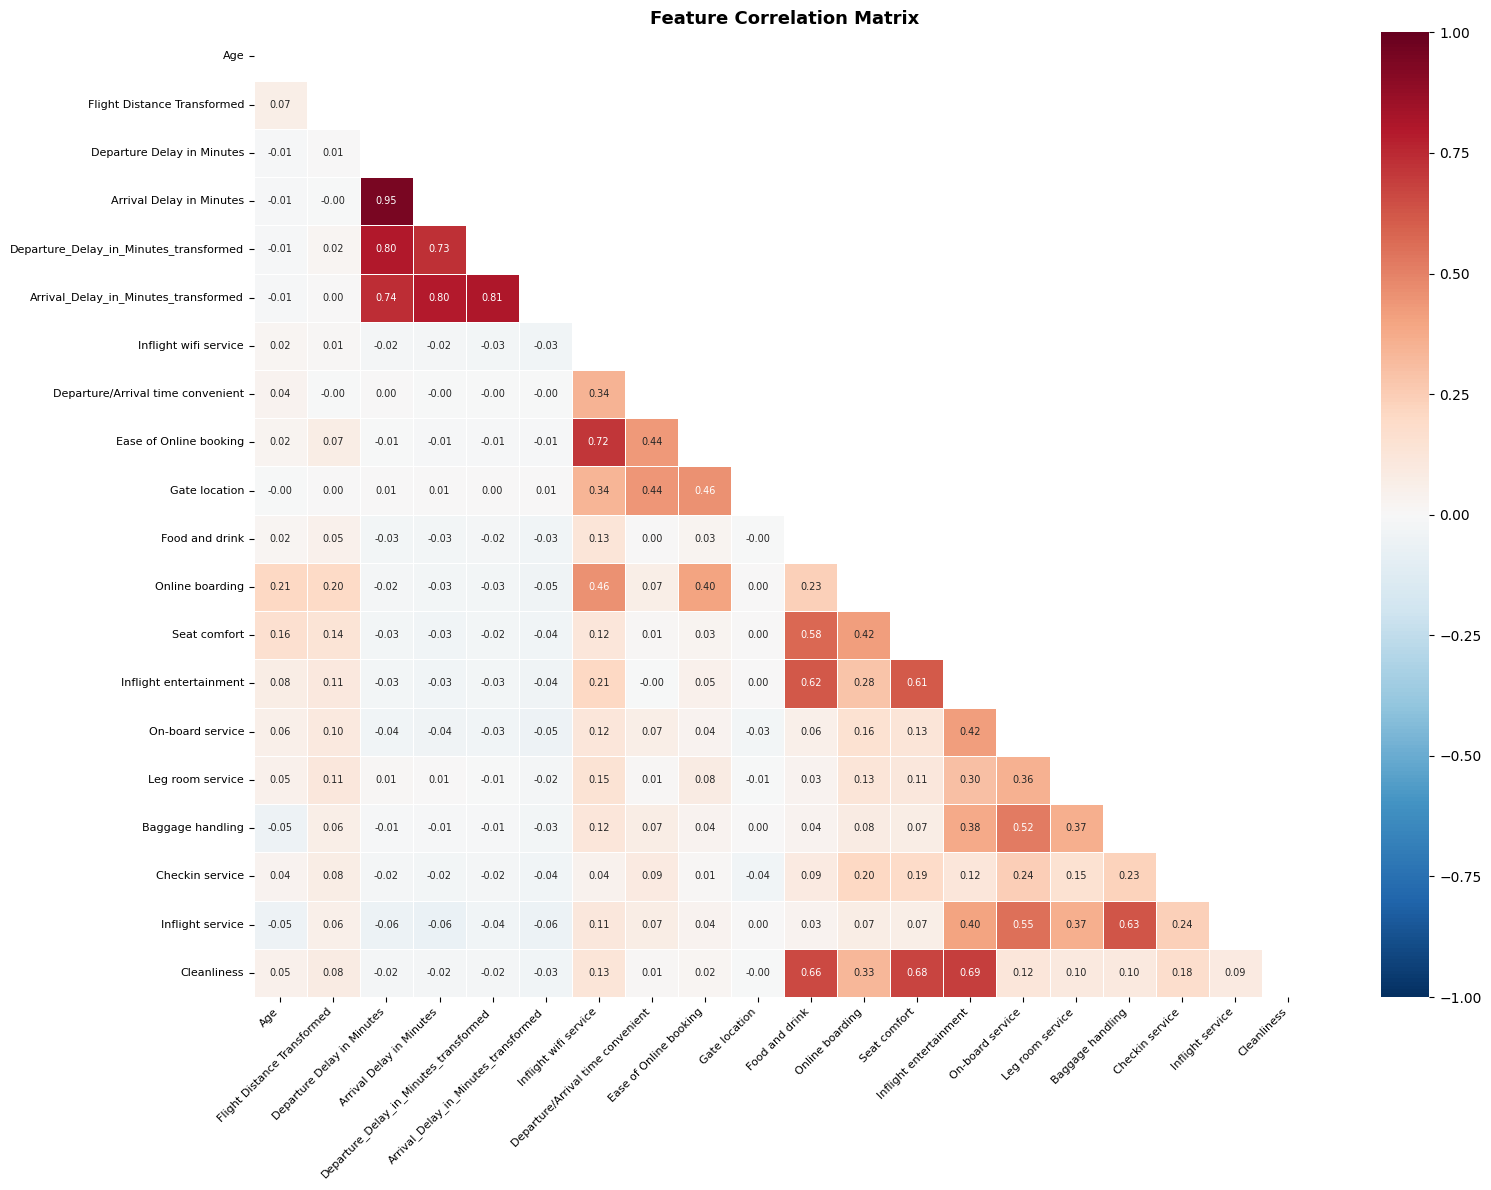

In [34]:
fig, ax = plt.subplots(figsize=(16, 12))

corr_matrix = train[vif_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    ax=ax,
    annot_kws={'size': 7},
    linewidths=0.5
)

ax.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150)
plt.show()

Dropped raw delay columns. Keeping transformed + binary versions.

=== PCA EXPLAINED VARIANCE ===
PC1: 26.89% variance (cumulative: 26.89%)
PC2: 18.49% variance (cumulative: 45.38%)
PC3: 14.11% variance (cumulative: 59.48%)
PC4: 8.18% variance (cumulative: 67.67%)
PC5: 6.62% variance (cumulative: 74.29%)
PC6: 4.80% variance (cumulative: 79.09%)
PC7: 4.25% variance (cumulative: 83.34%)
PC8: 3.61% variance (cumulative: 86.95%)
PC9: 3.10% variance (cumulative: 90.06%) ← 90% threshold
PC10: 2.40% variance (cumulative: 92.45%)
PC11: 2.13% variance (cumulative: 94.58%)
PC12: 2.12% variance (cumulative: 96.70%) ← 95% threshold
PC13: 1.95% variance (cumulative: 98.65%)
PC14: 1.35% variance (cumulative: 100.00%)


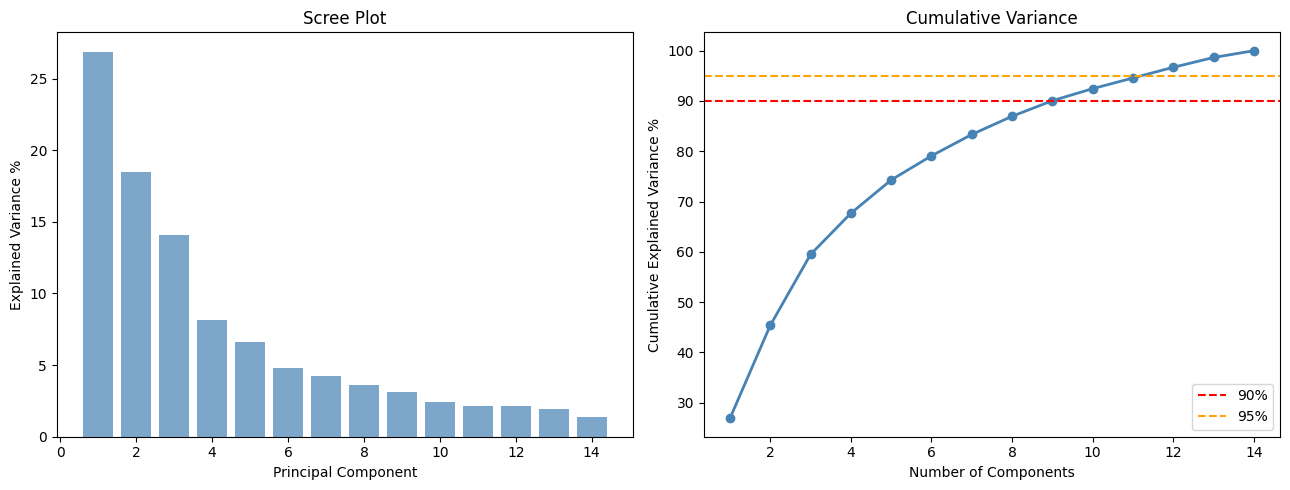

In [37]:
# --- Strategy 1: Drop redundant delay columns ---
# Keep: binary flags + transformed versions (better distributional properties)
# Drop: raw scaled delay columns (same info, worse distribution)
cols_to_drop_delay = [
    'Departure Delay in Minutes',
    'Arrival Delay in Minutes'
]
train.drop(columns=cols_to_drop_delay, inplace=True)
test.drop(columns=cols_to_drop_delay, inplace=True)

print("Dropped raw delay columns. Keeping transformed + binary versions.")

# --- Strategy 2: PCA on service rating block ---
# Split ordinal cols into two groups based on VIF findings
high_vif_ratings = [
    'Inflight entertainment', 'Inflight service', 'Cleanliness',
    'Baggage handling', 'Seat comfort', 'Food and drink',
    'On-board service', 'Leg room service', 'Checkin service',
    'Online boarding', 'Inflight wifi service', 'Ease of Online booking',
    'Gate location', 'Departure/Arrival time convenient'
]

# Fit PCA on training data only
pca = PCA(random_state=42)
pca.fit(train[high_vif_ratings])

# Explained variance analysis
cumvar = np.cumsum(pca.explained_variance_ratio_)
n_components_90 = np.argmax(cumvar >= 0.90) + 1
n_components_95 = np.argmax(cumvar >= 0.95) + 1

print(f"\n=== PCA EXPLAINED VARIANCE ===")
for i, (var, cumv) in enumerate(
    zip(pca.explained_variance_ratio_, cumvar)
):
    marker = ""
    if i + 1 == n_components_90:
        marker = " ← 90% threshold"
    if i + 1 == n_components_95:
        marker = " ← 95% threshold"
    print(f"PC{i+1}: {var*100:.2f}% variance "
          f"(cumulative: {cumv*100:.2f}%){marker}")
    if cumv >= 0.99:
        break

# Visualize scree plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.bar(range(1, len(pca.explained_variance_ratio_)+1),
        pca.explained_variance_ratio_ * 100,
        color='steelblue', alpha=0.7)
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance %')
ax1.set_title('Scree Plot')

ax2.plot(range(1, len(cumvar)+1), cumvar * 100,
         marker='o', color='steelblue', linewidth=2)
ax2.axhline(y=90, color='red', linestyle='--', label='90%')
ax2.axhline(y=95, color='orange', linestyle='--', label='95%')
ax2.set_xlabel('Number of Components')
ax2.set_ylabel('Cumulative Explained Variance %')
ax2.set_title('Cumulative Variance')
ax2.legend()

plt.tight_layout()
plt.savefig('pca_scree.png', dpi=150)
plt.show()

In [38]:
# Apply PCA with 9 components (90% threshold)
n_components = 9
pca_final = PCA(n_components=n_components, random_state=42)

# Fit on train, transform both
train_pca = pca_final.fit_transform(train[high_vif_ratings])
test_pca = pca_final.transform(test[high_vif_ratings])

# Create component dataframes
pca_cols = [f'service_PC{i+1}' for i in range(n_components)]
train_pca_df = pd.DataFrame(train_pca, columns=pca_cols, index=train.index)
test_pca_df = pd.DataFrame(test_pca, columns=pca_cols, index=test.index)

# --- Loadings: what does each PC represent? ---
loadings = pd.DataFrame(
    pca_final.components_.T,
    index=high_vif_ratings,
    columns=pca_cols
).round(3)

print("=== PCA LOADINGS (contribution of each feature to each PC) ===")
print(loadings.to_string())

print("\n=== TOP 3 FEATURES PER COMPONENT ===")
for pc in pca_cols[:5]:  # first 5 components
    top = loadings[pc].abs().sort_values(ascending=False).head(3)
    direction = loadings[pc][top.index]
    print(f"\n{pc} ({pca_final.explained_variance_ratio_[int(pc[-1])-1]*100:.1f}% var):")
    for feat, val in direction.items():
        sign = "↑" if val > 0 else "↓"
        print(f"  {sign} {feat}: {val:.3f}")

# --- Merge PCA components back into main dataframe ---
# Drop original rating columns
train.drop(columns=high_vif_ratings, inplace=True)
test.drop(columns=high_vif_ratings, inplace=True)

train = pd.concat([train, train_pca_df], axis=1)
test = pd.concat([test, test_pca_df], axis=1)

print(f"\n=== FINAL SHAPE AFTER PCA ===")
print(f"Train: {train.shape}")
print(f"Test:  {test.shape}")
print(f"\nColumns:")
print(train.columns.tolist())

=== PCA LOADINGS (contribution of each feature to each PC) ===
                                   service_PC1  service_PC2  service_PC3  service_PC4  service_PC5  service_PC6  service_PC7  service_PC8  service_PC9
Inflight entertainment                   0.426       -0.218       -0.004       -0.139       -0.251       -0.086        0.016       -0.044        0.029
Inflight service                         0.202       -0.051        0.434       -0.073       -0.064       -0.222        0.078       -0.063       -0.335
Cleanliness                              0.365       -0.216       -0.273       -0.145        0.021        0.045        0.020       -0.028       -0.047
Baggage handling                         0.201       -0.047        0.426       -0.060       -0.059       -0.200        0.083       -0.092       -0.507
Seat comfort                             0.358       -0.196       -0.271       -0.044        0.117        0.101       -0.050        0.408       -0.150
Food and drink                 

In [39]:
# Raw Flight Distance was superseded by transformed version
train.drop(columns=['Flight Distance'], inplace=True)
test.drop(columns=['Flight Distance'], inplace=True)

print("Columns after cleanup:")
print(train.columns.tolist())
print(f"\nFinal shape: {train.shape}")

Columns after cleanup:
['Age', 'Departure_Arrival_time_convenient_not_used', 'Ease_of_Online_booking_not_used', 'Inflight_wifi_service_not_used', 'Online_boarding_not_used', 'Flight Distance Transformed', 'Departure_Delay_in_Minutes_binary', 'Departure_Delay_in_Minutes_transformed', 'Arrival_Delay_in_Minutes_binary', 'Arrival_Delay_in_Minutes_transformed', 'is_loyal', 'is_business_travel', 'is_male', 'class_Business', 'class_Eco', 'class_Eco Plus', 'business_travel_x_business_class', 'personal_travel_x_eco', 'ecoplus_personal', 'satisfaction_binary', 'service_PC1', 'service_PC2', 'service_PC3', 'service_PC4', 'service_PC5', 'service_PC6', 'service_PC7', 'service_PC8', 'service_PC9']

Final shape: (103904, 29)


In [40]:
# Exclude binary/dummy columns and target - VIF on continuous features only
vif_final_cols = [
    'Age', 'Flight Distance Transformed',
    'Departure_Delay_in_Minutes_transformed',
    'Arrival_Delay_in_Minutes_transformed',
    'service_PC1', 'service_PC2', 'service_PC3',
    'service_PC4', 'service_PC5', 'service_PC6',
    'service_PC7', 'service_PC8', 'service_PC9'
]

vif_final = pd.DataFrame({
    'Feature': vif_final_cols,
    'VIF': [variance_inflation_factor(
                train[vif_final_cols].values, i)
            for i in range(len(vif_final_cols))]
}).sort_values('VIF', ascending=False).round(3)

print("=== VIF AFTER MULTICOLLINEARITY RESOLUTION ===")
print(vif_final.to_string(index=False))

=== VIF AFTER MULTICOLLINEARITY RESOLUTION ===
                               Feature   VIF
  Arrival_Delay_in_Minutes_transformed 4.425
Departure_Delay_in_Minutes_transformed 4.420
                                   Age 1.085
           Flight Distance Transformed 1.062
                           service_PC8 1.053
                           service_PC1 1.042
                           service_PC4 1.018
                           service_PC7 1.013
                           service_PC5 1.009
                           service_PC6 1.006
                           service_PC3 1.005
                           service_PC9 1.001
                           service_PC2 1.001


### Feature Selection

In [41]:
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [42]:
# Setup
feature_cols = [c for c in train.columns if c != 'satisfaction_binary']
X = train[feature_cols]
y = train['satisfaction_binary']

print(f"Features going into selection: {len(feature_cols)}")
print(feature_cols)

# --- Method 1: Mutual Information ---
print("\n=== METHOD 1: MUTUAL INFORMATION ===")
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_df = pd.DataFrame({
    'Feature': feature_cols,
    'MI Score': mi_scores
}).sort_values('MI Score', ascending=False).round(4)
print(mi_df.to_string(index=False))

# --- Method 2: RFE with Random Forest ---
print("\n=== METHOD 2: RFE (Random Forest, select top 15) ===")
rf_rfe = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1
)
rfe = RFE(estimator=rf_rfe, n_features_to_select=15, step=2)
rfe.fit(X, y)

rfe_df = pd.DataFrame({
    'Feature': feature_cols,
    'Selected': rfe.support_,
    'Rank': rfe.ranking_
}).sort_values('Rank')
print(rfe_df.to_string(index=False))

# --- Method 3: L1 Logistic Regression ---
print("\n=== METHOD 3: L1 LOGISTIC REGRESSION ===")
lr_l1 = LogisticRegression(
    penalty='l1', solver='liblinear', C=0.1,
    random_state=42, max_iter=1000
)
lr_l1.fit(X, y)

l1_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr_l1.coef_[0],
    'Abs Coefficient': np.abs(lr_l1.coef_[0]),
    'Zeroed Out': lr_l1.coef_[0] == 0
}).sort_values('Abs Coefficient', ascending=False).round(4)
print(l1_df.to_string(index=False))

Features going into selection: 28
['Age', 'Departure_Arrival_time_convenient_not_used', 'Ease_of_Online_booking_not_used', 'Inflight_wifi_service_not_used', 'Online_boarding_not_used', 'Flight Distance Transformed', 'Departure_Delay_in_Minutes_binary', 'Departure_Delay_in_Minutes_transformed', 'Arrival_Delay_in_Minutes_binary', 'Arrival_Delay_in_Minutes_transformed', 'is_loyal', 'is_business_travel', 'is_male', 'class_Business', 'class_Eco', 'class_Eco Plus', 'business_travel_x_business_class', 'personal_travel_x_eco', 'ecoplus_personal', 'service_PC1', 'service_PC2', 'service_PC3', 'service_PC4', 'service_PC5', 'service_PC6', 'service_PC7', 'service_PC8', 'service_PC9']

=== METHOD 1: MUTUAL INFORMATION ===
                                   Feature  MI Score
                               service_PC1     0.206
          business_travel_x_business_class     0.158
                               service_PC4     0.149
                               service_PC2     0.146
                 

In [43]:
# Features selected by at least 2 of 3 methods
# or with strong theoretical justification

final_features = [
    # Strong consensus
    'service_PC1',           # Cabin comfort — top MI, RFE, L1
    'service_PC2',           # Digital experience
    'service_PC3',           # Staff service
    'service_PC4',           # Online vs timing contrast
    'service_PC5',           # Checkin dimension
    'service_PC6',           # Minor but RFE selected
    'service_PC7',           # Minor but RFE selected
    'service_PC8',           # Minor but RFE selected
    'service_PC9',           # Minor, keep for completeness
    'is_business_travel',    # 2nd strongest L1, 6th MI
    'is_loyal',              # Strong L1, RFE selected
    'business_travel_x_business_class',  # 2nd MI, RFE, L1
    'personal_travel_x_eco', # 14th MI, theoretical value
    'ecoplus_personal',      # Weak but domain-justified
    'class_Business',        # 5th MI, RFE selected
    'class_Eco',             # 10th MI, RFE selected
    'class_Eco Plus',        # Weak but needed for completeness
    'Age',                   # RFE selected, moderate MI
    'Flight Distance Transformed',  # Moderate MI
    'Inflight_wifi_service_not_used',  # L1=11, RFE selected
    'Arrival_Delay_in_Minutes_transformed',  # L1 signal
    'Departure_Arrival_time_convenient_not_used',  # L1 signal
    'Ease_of_Online_booking_not_used',   # Some L1 signal
]

# Drop confirmed noise
drop_features = [
    'is_male',                              # No signal anywhere
    'Departure_Delay_in_Minutes_binary',    # Weakest delay feature
    'Arrival_Delay_in_Minutes_binary',      # Zeroed by L1
    'Departure_Delay_in_Minutes_transformed', # Dominated by arrival
    'Online_boarding_not_used',             # Weak across all methods
]

X_final = train[final_features]
y_final = train['satisfaction_binary']

X_test_final = test[final_features]
y_test_final = test['satisfaction_binary']

print("=== FINAL FEATURE SET ===")
print(f"Features retained: {len(final_features)}")
print(f"Features dropped: {len(drop_features)}")
print(f"\nDropped: {drop_features}")
print(f"\nX_final shape: {X_final.shape}")
print(f"X_test shape:  {X_test_final.shape}")

# Quick sanity check - class balance in final set
print(f"\nTarget distribution:")
print(y_final.value_counts(normalize=True).mul(100).round(2))

=== FINAL FEATURE SET ===
Features retained: 23
Features dropped: 5

Dropped: ['is_male', 'Departure_Delay_in_Minutes_binary', 'Arrival_Delay_in_Minutes_binary', 'Departure_Delay_in_Minutes_transformed', 'Online_boarding_not_used']

X_final shape: (103904, 23)
X_test shape:  (25976, 23)

Target distribution:
satisfaction_binary
0   56.670
1   43.330
Name: proportion, dtype: float64


# Modelling

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, f1_score,
                             precision_score, recall_score)
import time

In [45]:
# Cross validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Models
models = {
    'Logistic Regression': LogisticRegression(
        C=1.0, max_iter=1000, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=15,
        min_samples_leaf=5, random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=6,
        learning_rate=0.1, subsample=0.8,
        colsample_bytree=0.8, random_state=42,
        eval_metric='logloss', verbosity=0
    )
}

scoring = ['roc_auc', 'f1', 'precision', 'recall']
results = {}

for name, model in models.items():
    print(f"\nTraining: {name}...")
    start = time.time()

    cv_results = cross_validate(
        model, X_final, y_final,
        cv=cv, scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    elapsed = time.time() - start
    results[name] = cv_results

    print(f"  Time: {elapsed:.1f}s")
    print(f"  ROC-AUC : {cv_results['test_roc_auc'].mean():.4f} "
          f"± {cv_results['test_roc_auc'].std():.4f}")
    print(f"  F1      : {cv_results['test_f1'].mean():.4f} "
          f"± {cv_results['test_f1'].std():.4f}")
    print(f"  Precision: {cv_results['test_precision'].mean():.4f} "
          f"± {cv_results['test_precision'].std():.4f}")
    print(f"  Recall  : {cv_results['test_recall'].mean():.4f} "
          f"± {cv_results['test_recall'].std():.4f}")
    print(f"  Train AUC: {cv_results['train_roc_auc'].mean():.4f} "
          f"(gap: {cv_results['train_roc_auc'].mean() - cv_results['test_roc_auc'].mean():.4f})")


Training: Logistic Regression...
  Time: 14.0s
  ROC-AUC : 0.9643 ± 0.0011
  F1      : 0.8864 ± 0.0036
  Precision: 0.8873 ± 0.0044
  Recall  : 0.8856 ± 0.0048
  Train AUC: 0.9644 (gap: 0.0001)

Training: Random Forest...
  Time: 337.5s
  ROC-AUC : 0.9833 ± 0.0005
  F1      : 0.9240 ± 0.0019
  Precision: 0.9435 ± 0.0025
  Recall  : 0.9053 ± 0.0030
  Train AUC: 0.9942 (gap: 0.0109)

Training: XGBoost...
  Time: 22.7s
  ROC-AUC : 0.9870 ± 0.0004
  F1      : 0.9330 ± 0.0022
  Precision: 0.9456 ± 0.0014
  Recall  : 0.9208 ± 0.0035
  Train AUC: 0.9932 (gap: 0.0062)


In [48]:
print("\n\n=== FINAL EVALUATION ON HELD-OUT TEST SET ===")

final_models = {}
for name, model in models.items():
    model.fit(X_final, y_final)
    final_models[name] = model

    y_pred = model.predict(X_test_final)
    y_prob = model.predict_proba(X_test_final)[:, 1]

    print(f"\n{name}:")
    print(f"  ROC-AUC  : {roc_auc_score(y_test_final, y_prob):.4f}")
    print(f"  F1       : {f1_score(y_test_final, y_pred):.4f}")
    print(f"  Precision: {precision_score(y_test_final, y_pred):.4f}")
    print(f"  Recall   : {recall_score(y_test_final, y_pred):.4f}")



=== FINAL EVALUATION ON HELD-OUT TEST SET ===

Logistic Regression:
  ROC-AUC  : 0.9642
  F1       : 0.8862
  Precision: 0.8855
  Recall   : 0.8869

Random Forest:
  ROC-AUC  : 0.9833
  F1       : 0.9256
  Precision: 0.9425
  Recall   : 0.9094

XGBoost:
  ROC-AUC  : 0.9868
  F1       : 0.9346
  Precision: 0.9456
  Recall   : 0.9239


# SHAP Interpretation

In [46]:
import shap

SHAP values shape: (25976, 23)
Test set shape:    (25976, 23)


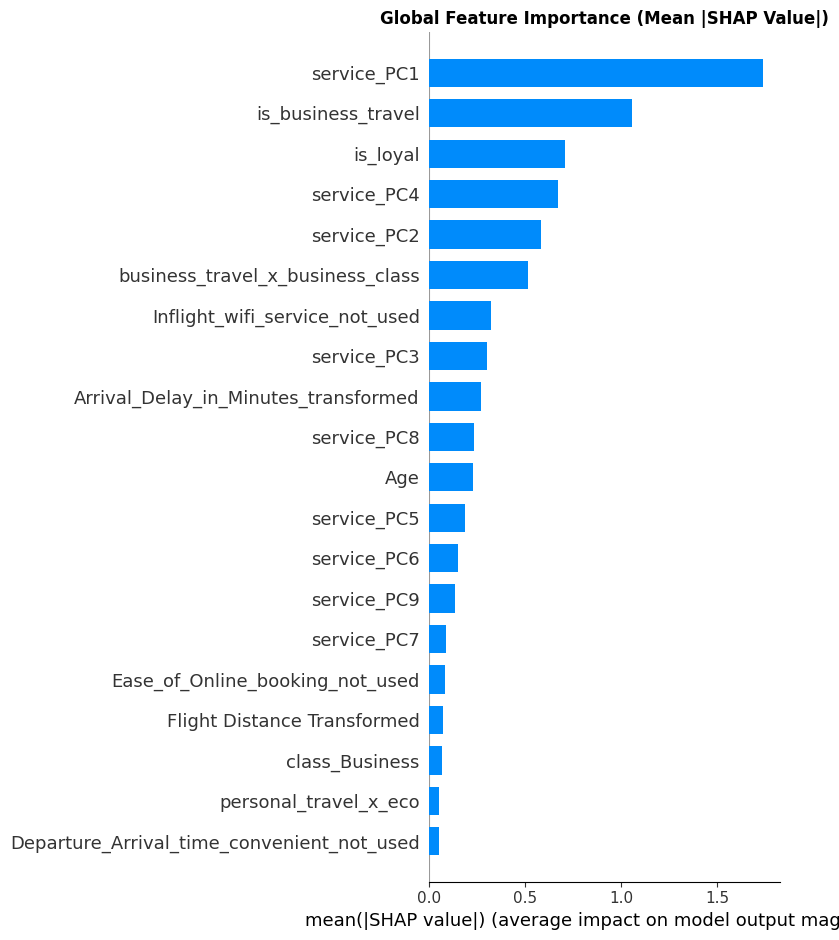

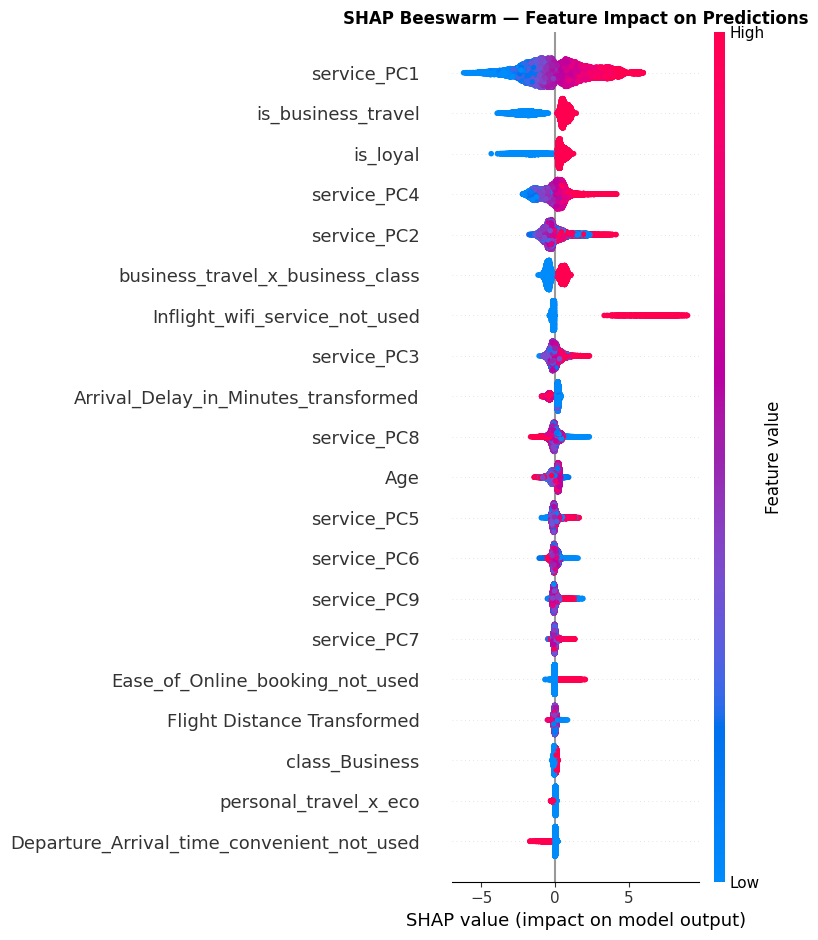


=== SHAP FEATURE IMPORTANCE ===
                                   Feature  Mean |SHAP|
                               service_PC1        1.742
                        is_business_travel        1.059
                                  is_loyal        0.707
                               service_PC4        0.671
                               service_PC2        0.583
          business_travel_x_business_class        0.515
            Inflight_wifi_service_not_used        0.321
                               service_PC3        0.298
      Arrival_Delay_in_Minutes_transformed        0.267
                               service_PC8        0.231
                                       Age        0.226
                               service_PC5        0.185
                               service_PC6        0.150
                               service_PC9        0.131
                               service_PC7        0.087
           Ease_of_Online_booking_not_used        0.080
               

In [49]:
# Use XGBoost as final model
xgb_model = final_models['XGBoost']

# SHAP TreeExplainer - optimized for tree models, exact not approximate
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_final)

print(f"SHAP values shape: {shap_values.shape}")
print(f"Test set shape:    {X_test_final.shape}")

# --- Plot 1: Global Feature Importance (mean |SHAP|) ---
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values, X_test_final,
    plot_type='bar',
    show=False
)
plt.title('Global Feature Importance (Mean |SHAP Value|)',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_importance.png', dpi=150)
plt.show()

# --- Plot 2: SHAP Beeswarm — direction + magnitude ---
plt.figure(figsize=(10, 9))
shap.summary_plot(
    shap_values, X_test_final,
    show=False
)
plt.title('SHAP Beeswarm — Feature Impact on Predictions',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150)
plt.show()

# --- Numerical SHAP importance ---
shap_importance = pd.DataFrame({
    'Feature': X_test_final.columns,
    'Mean |SHAP|': np.abs(shap_values).mean(axis=0)
}).sort_values('Mean |SHAP|', ascending=False).round(4)

print("\n=== SHAP FEATURE IMPORTANCE ===")
print(shap_importance.to_string(index=False))

In [50]:
# --- Single prediction explanation ---
# Find one satisfied and one dissatisfied passenger
satisfied_idx = X_test_final[y_test_final == 1].index[0]
dissatisfied_idx = X_test_final[y_test_final == 0].index[0]

print("\n=== SINGLE PREDICTION BREAKDOWN ===")
for label, idx in [('SATISFIED', satisfied_idx),
                    ('DISSATISFIED', dissatisfied_idx)]:
    print(f"\n--- {label} PASSENGER ---")
    row_shap = shap_values[X_test_final.index.get_loc(idx)]
    base = explainer.expected_value
    prediction = xgb_model.predict_proba(
        X_test_final.loc[[idx]]
    )[0][1]

    contrib = pd.DataFrame({
        'Feature': X_test_final.columns,
        'Value': X_test_final.loc[idx].values,
        'SHAP': row_shap
    }).sort_values('SHAP', ascending=False)

    print(f"Base rate: {base:.3f} | "
          f"Final prediction: {prediction:.3f}")
    print("Top drivers toward satisfied:")
    print(contrib.head(5).to_string(index=False))
    print("Top drivers toward dissatisfied:")
    print(contrib.tail(5).to_string(index=False))


=== SINGLE PREDICTION BREAKDOWN ===

--- SATISFIED PASSENGER ---
Base rate: -0.278 | Final prediction: 0.979
Top drivers toward satisfied:
                    Feature  Value  SHAP
                service_PC1  3.289 3.092
         is_business_travel  1.000 1.095
                   is_loyal  1.000 0.717
                service_PC3  1.676 0.361
Flight Distance Transformed -1.686 0.292
Top drivers toward dissatisfied:
                             Feature  Value   SHAP
                         service_PC2  1.095 -0.089
                         service_PC9 -0.069 -0.101
                         service_PC8  0.240 -0.153
Arrival_Delay_in_Minutes_transformed  1.442 -0.495
    business_travel_x_business_class  0.000 -0.597

--- DISSATISFIED PASSENGER ---
Base rate: -0.278 | Final prediction: 0.006
Top drivers toward satisfied:
                             Feature  Value  SHAP
                  is_business_travel  1.000 0.383
                         service_PC6 -1.700 0.267
                   